# Explore here

In [71]:
#Librerias

import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Paso 1: Carga del conjunto de datos

In [ ]:
df = pd.read_csv('https://storage.googleapis.com/breathecode/project-files/bank-marketing-campaign-data.csv', sep=';')
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


## Paso 2: Realiza un EDA completo

### Paso 1 EDA: Planteamiento del problema y recopilación de datos

El banco portugués está teniendo una disminución en sus ingresos, por lo que quieren poder identificar a los clientes existentes que tienen una mayor probabilidad de contratar un depósito a largo plazo. Esto permitirá que el banco centre sus esfuerzos de marketing en esos clientes y evitará perder dinero y tiempo en clientes que probablemente no se suscribirán.

Para abordar este problema crearemos un algoritmo de clasificación que ayude a predecir si un cliente contratará o no un depósito a largo plazo.

Nuestra variabe objetivo es 'y'.

### Paso 2 EDA: Exploración y limpieza de datos

In [52]:
df.shape

(41188, 21)

In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

Primeras conclusiones
- Existen un total de 41188 filas (en este caso, personas) y 21 columnas, de entre las que encontramos el objetivo o clase a predecir, 'y'.
- A simple vista podemos inferir que no tenemos ningun valor nulo.
- Los datos tienen 10 variables numéricas y 11 variables categóricas.


Nuestras variables son:

**'age'**: Edad del cliente

**'job'**: Tipo de trabajo

**'marital'**: Estado civil

**'education'**: Nivel de educación

**'default'**: ¿Tiene crédito actualmente?

**'housing'**: ¿Tiene un préstamo de vivienda?

**'loan'**: ¿Tiene un préstamo personal?

**'contact'**: Tipo de comunicación de contacto

**'month'**: Último mes en el que se le ha contactado

**'day_of_week'**: Último día en el que se le ha contactado

**'duration'**: Duración del contacto previo en segundos

**'campaign'**: Número de contactos realizados durante esta campaña al cliente

**'pdays'**: Número de días que transcurrieron desde la última campaña hasta que fue contactado

**'previous'**: Número de contactos realizados durante la campaña anterior al cliente

**'poutcome'**: Resultado de la campaña de marketing anterior

**'emp.var.rate'**: Tasa de variación del empleo. Indicador trimestral

**'cons.price.idx'**: Índice de precios al consumidor. Indicador mensual

**'cons.conf.idx'**: Índice de confianza del consumidor. Indicador mensual

**'euribor3m'**: Tasa EURIBOR 3 meses. Indicador diario

**'nr.employed'**: Número de empleados. Indicador trimestral

**'y'**: TARGET. El cliente contrata un depósito a largo plazo o no.

**Eliminar duplicados**

In [56]:
df.duplicated().sum()

np.int64(12)

Tenemos 12 filas duplicadas por lo que procedemos a eliminarlas.

In [57]:
if df.duplicated().sum():
    df.drop_duplicates(inplace=True)
    
df.shape

(41176, 21)

Ahora nos quedamos con 41176 filas y las mismas 21 columnas.

**Eliminar información irrelevante**

De todas las columnas, creo que ninguna es irrelevante en este punto, primero veamos cuanta relación tienen con la variable objetivo.

### Paso 3 EDA: Análisis de variables univariante

#### Variables Categóricas

In [68]:
categoricas = df.select_dtypes(include=['str']).columns.tolist()
categoricas

['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'day_of_week',
 'poutcome',
 'y']

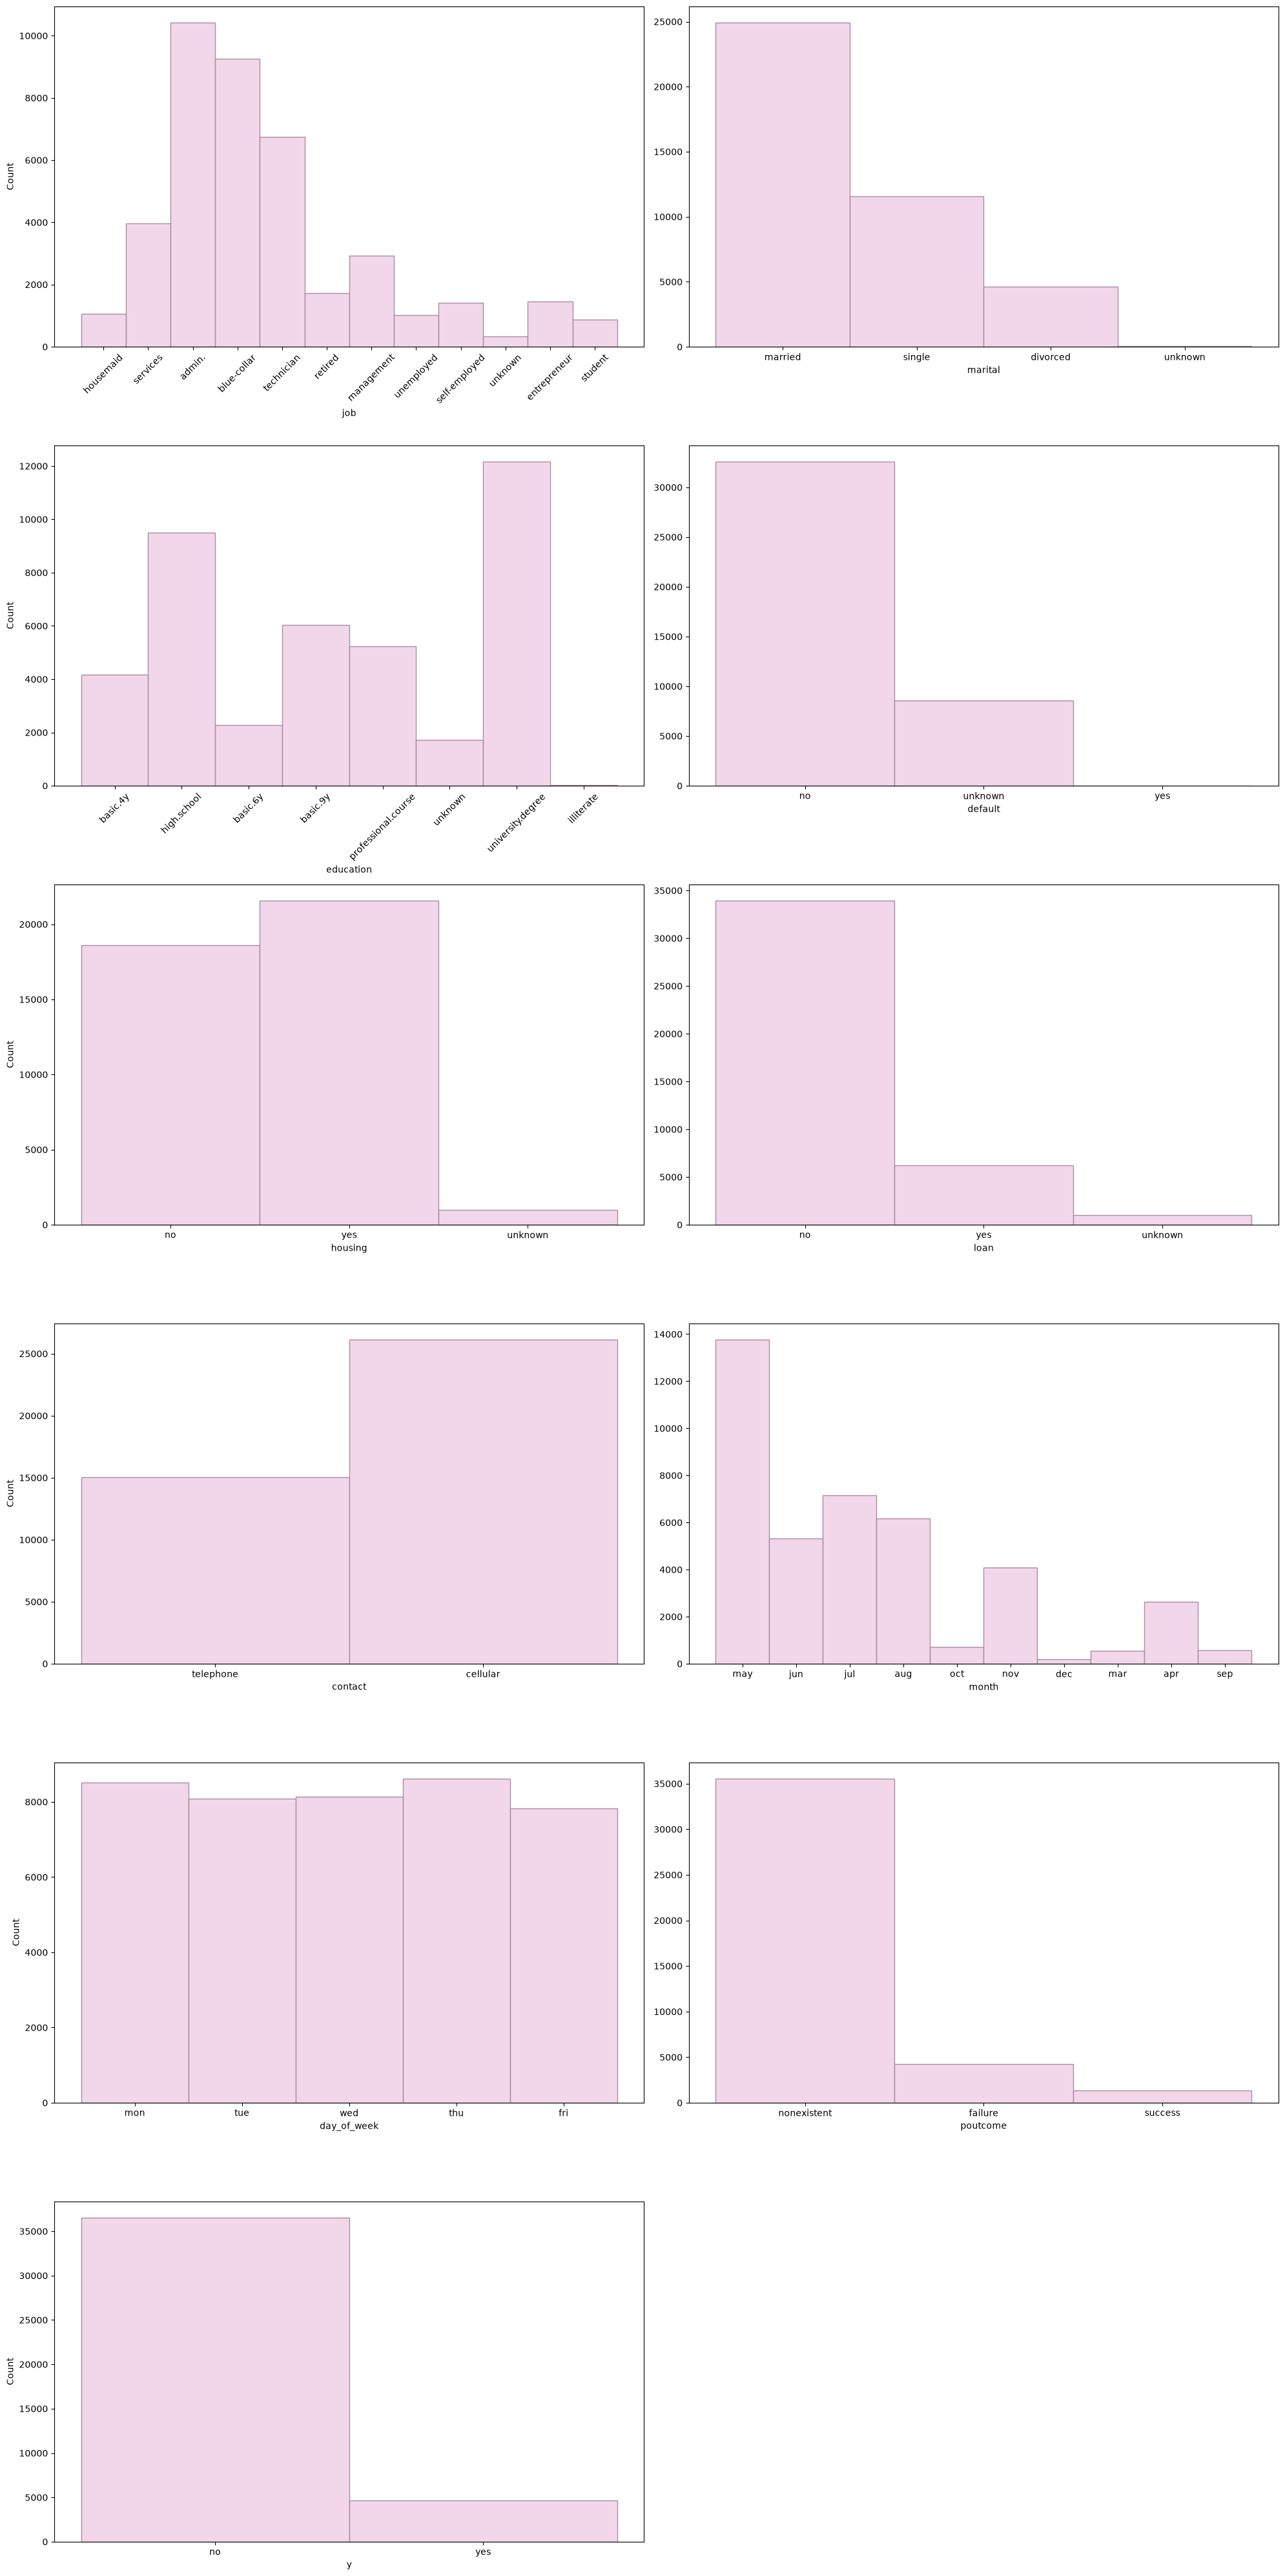

In [122]:
fig, axis = plt.subplots(6, 2, figsize = (20,40))

sns.histplot(ax = axis[0,0], data = df,x = 'job', color='#EDCAE2', edgecolor='#AB8CA3').tick_params(axis='x', rotation=45)
sns.histplot(ax = axis[0,1], data = df,x = 'marital', color='#EDCAE2', edgecolor='#AB8CA3').set(ylabel = None)
sns.histplot(ax = axis[1,0], data = df,x = 'education', color='#EDCAE2', edgecolor='#AB8CA3')
axis[1,0].tick_params(axis='x', rotation=45)
sns.histplot(ax = axis[1,1], data = df,x = 'default', color='#EDCAE2', edgecolor='#AB8CA3').set(ylabel = None)
sns.histplot(ax = axis[2,0], data = df,x = 'housing', color='#EDCAE2', edgecolor='#AB8CA3')
sns.histplot(ax = axis[2,1], data = df,x = 'loan', color='#EDCAE2', edgecolor='#AB8CA3').set(ylabel = None)
sns.histplot(ax = axis[3,0], data = df,x = 'contact', color='#EDCAE2', edgecolor='#AB8CA3')
sns.histplot(ax = axis[3,1], data = df,x = 'month', color='#EDCAE2', edgecolor='#AB8CA3').set(ylabel= None)
sns.histplot(ax = axis[4,0], data = df,x = 'day_of_week', color='#EDCAE2', edgecolor='#AB8CA3')
sns.histplot(ax = axis[4,1], data = df,x = 'poutcome', color='#EDCAE2', edgecolor='#AB8CA3').set(ylabel = None)
sns.histplot(ax = axis[5,0], data = df,x = 'y', color='#EDCAE2', edgecolor='#AB8CA3')

fig.delaxes(axis[5,1])

plt.tight_layout()
plt.show()

Con las representaciones de cada variable, podemos determinar que:

- **'job'**: La mayoria de las personas tienen una ocupación de clasificacion "admin." (administrativos) con más de 10.000 observaciones y la siguiente mayoria son personas con una ocupación de clasificacion "blue_collar" (operarios) con más de 9.000 observaciones. Las clasificaciones de ocupaciones "housemaid" (dueñ@ de casa), "retired" (jubilado), "unemployed" (desempleado), "self-employed" (trabajadores por cuenta propia), "unknown" (desconocido), "entrepreneur" (emprendedor) y "student" (estudiante) tienen menos de 2.000 observaciones cada una. Más del 50% del universo de los datos corresponden a ocupaciones "admin." (administrativos), "blue_collar" (operarios) y "technician" (técnicos).

- **'marital'**: La clasificaión "married" (casad@) tiene la amplia mayoría de observaciones, teniendo más del 50% del universo de los datos. Y la minoría la tiene la clasificación "divorced" (divorciad@), con menos de 5.000 observaciones. Tenemos algunas observaciones para clasificación "unknown" (desconocido).

- **'education'**: Más del 50% de las personas tiene un nivel educativo "university.degree" (grado universitario), "high.school" (secundaria completa). 

- **'default'**: Más de el 70% no tiene créditos actualmente, y la cantidad de personas que si tiene es prácticamente de 0 observaciones. Teniendo una variabilidad casi nula. 

- **'housing'**: La distribución entre quienes si tienen un préstamo para una vivienda y quienes no, está bastante balanceado. Con una diferencia aproximada de 2.000 observaciones más para quienes si tienen uhn préstamo de vivienda.

- **'loan'**: La amplia mayoria la obtiene el "no", que representa los que no poseen un préstamo personal, con 33.000 observaciones aproximadamente, mientras el "si" tiene apenas 
3.000 observaciones.

- **'contact'**: La forma de contacto que predomina es "cellular", con lo que se puede inferir que tienen una buena accesibilidad a los clientes.

- **'month'**: Como último mes de contacto, se refleja una furte mayoría en el mes de mayo. Luego entre los meses junio, julio, agosto y noviembre, presentan un poco más de balance entre ellos. Los demás meses poseen mínimas observaciones.

- **'day_of_week'**: La distribución entre en qué día se contacto al cliente es bastante uniforme.

- **'poutcome'**: La amplia mayoría se la lleva la opción "nonexistent", lo que quiere decir que un gran porcentaje de los datos, son de personas que no las habían contactado en campañas anteriores.

- **'y'**: La relación entre quienes finalmente contratan un depósito a largo plazo y quienes no es inmensa. El "no" posee más de 35.000 observaciones, dejando muy desbalanceado el dataset.

#### Variables Numéricas

In [42]:
numericas = df.select_dtypes(exclude=['str']).columns.tolist()
numericas

['age',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'emp.var.rate',
 'cons.price.idx',
 'cons.conf.idx',
 'euribor3m',
 'nr.employed']

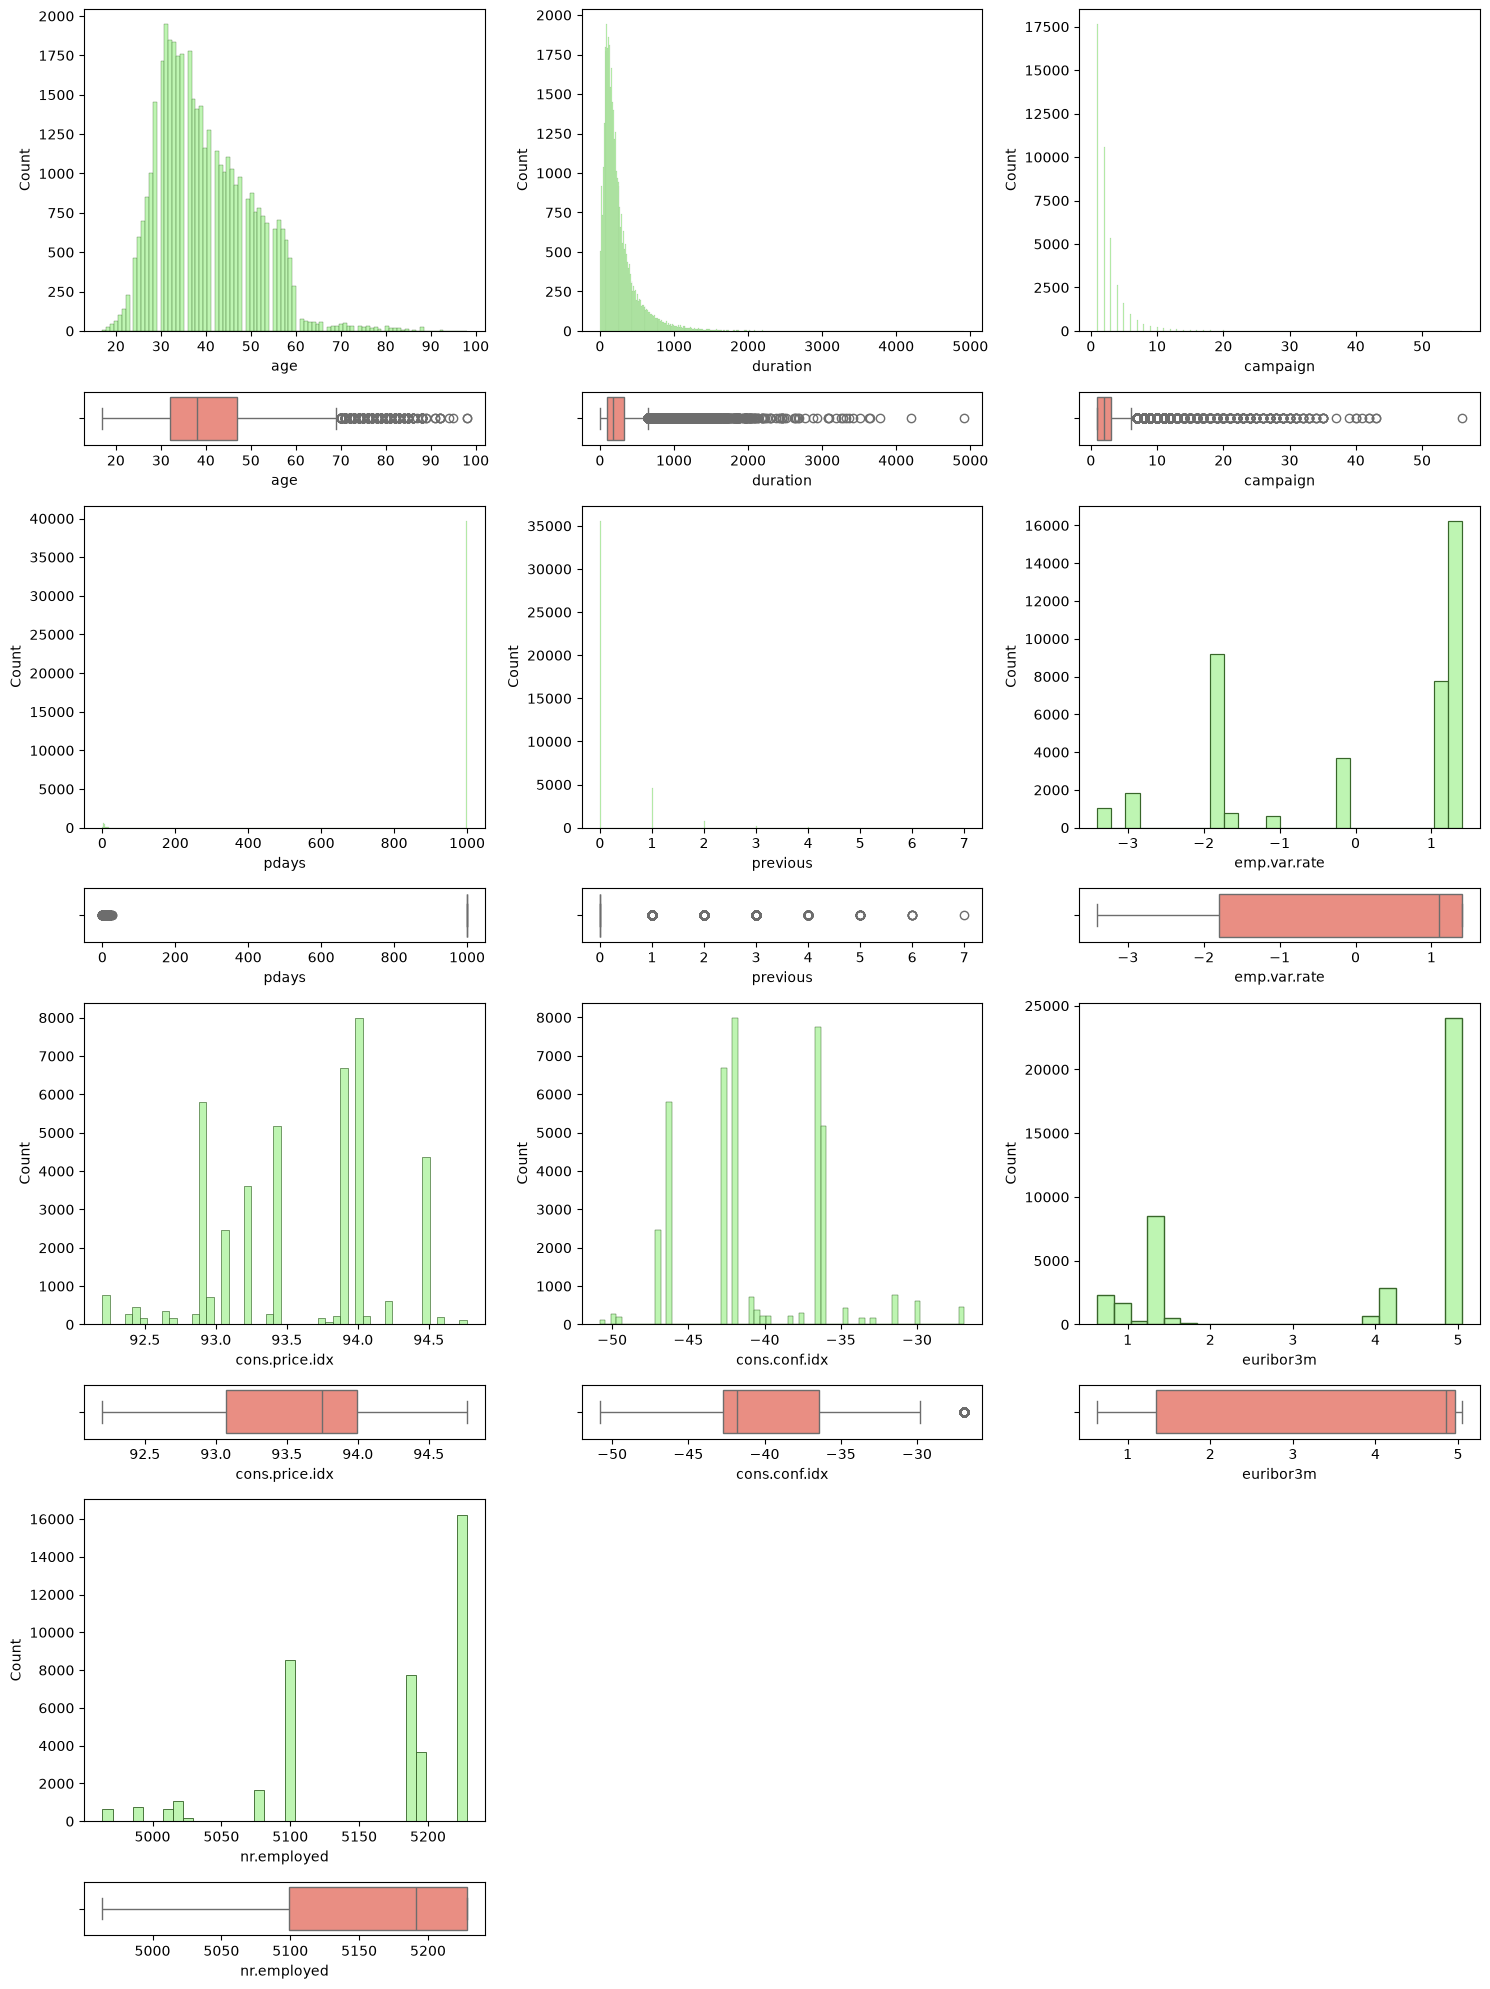

In [134]:
fig, axis = plt.subplots(8,3, figsize= (15,20),gridspec_kw= {"height_ratios":[6,1,6,1,6,1,6,1]})

sns.histplot(ax = axis[0,0], data = df, x = 'age', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[1,0], data = df, x = 'age', color='salmon')

sns.histplot(ax = axis[0,1], data = df, x = 'duration', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[1,1], data = df, x = 'duration', color='salmon')

sns.histplot(ax = axis[0,2], data = df, x = 'campaign', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[1,2], data = df, x = 'campaign', color='salmon')

sns.histplot(ax = axis[2,0], data = df, x = 'pdays', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[3,0], data = df, x = 'pdays', color='salmon')

sns.histplot(ax = axis[2,1], data = df, x = 'previous', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[3,1], data = df, x = 'previous', color='salmon')

sns.histplot(ax = axis[2,2], data = df, x = 'emp.var.rate', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[3,2], data = df, x = 'emp.var.rate', color='salmon')

sns.histplot(ax = axis[4,0], data = df, x = 'cons.price.idx', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[5,0], data = df, x = 'cons.price.idx', color='salmon')

sns.histplot(ax = axis[4,1], data = df, x = 'cons.conf.idx', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[5,1], data = df, x = 'cons.conf.idx', color='salmon')

sns.histplot(ax = axis[4,2], data = df, x = 'euribor3m', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[5,2], data = df, x = 'euribor3m', color='salmon')

sns.histplot(ax = axis[6,0], data = df, x = 'nr.employed', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[7,0], data = df, x = 'nr.employed', color='salmon')

fig.delaxes(axis[6,1])
fig.delaxes(axis[6,2])
fig.delaxes(axis[7,1])
fig.delaxes(axis[7,2])

plt.tight_layout()
plt.show()




Aanlizando los gráficos podemos inferir que:

- **'age'**: Los datos presentan una distribución sesgada hacia la derecha, y se concentran principalmente entre 30 y 50 años. Podemos observar varios valores atípicos sobre 70 años.

- **'duration'**: Los datos muestran que la mayoría de las llamadas duran aproximadamente menos de 200 segundos, y a la vez tenemos muchísimos valores atípicos sobre 700 segundos aprox.

- **'campaign'**: La gran mayoría de los clientes han recibido 2 llamados durante la campaña y podemos observar algunos valores atípicos sobre 6 llamados, incluso un valor atípico mayor a 50, lo que podría ser un error.

- **'pdays'**: Casi la totalidad de los datos estan situados en el valor 999, que puedo entender que implica que no fueron contactados anteriormente, y tenemos uns pocos valores atípicos que nos muestra la cantidad de días que han pasado desde el contacto con algunos clientes, pero debido a lo pocos clientes que son, la variable no aporta mucha relevancia.

- **'previous'**: Nuevamente los datos nos muestran que la amplia mayoría de clientes no ha sido contactado en campañas anteriores, teniendo apenas 5.000(aprox) clientes que si lo han sido. Con esto podemos inferir que esta campaña cuenta con una mayoría amplia de clientes nuevos.

- **'emp.var.rate'**: Podemos observar dos bloques marcados, uno con valores positivos entre 1 y 2, y otro con valores negativos poquito mayores a -2. No tenemos valores atípicos.

- **'cons.price.idx'**: Los datos no presentan una distribución normal y se comporta de forma multimodal. No se observan valores atípicos.

- **'cons.conf.idx'**: Los datos no presentan una distribución normal y se comporta de forma multimodal. Solamente tenemos datos negativos, concentándose entre -45 y -35. Mínimos valores atípicos.

- **'euribor3m'**: Gran mayoría concentrada en valores aproximadamente a 5 sin valores atípicos.

- **'nr.employed'**: Los datos se concentran en valores entre 5100 y 5250 sin balores atípicos.

### Paso 4 EDA: Análisis de variables multivariante

#### Numérico-numérico

Primero transformaremos a numérica nuestra variable objetivo ***'y'***



In [135]:
df['y'] = df['y'].map({'no': 0, 'yes': 1})

print(df['y'].value_counts())

y
0    36537
1     4639
Name: count, dtype: int64


Ahora analizaremos nuestras variables numéricas con respecto a nuestra variable objetivo.

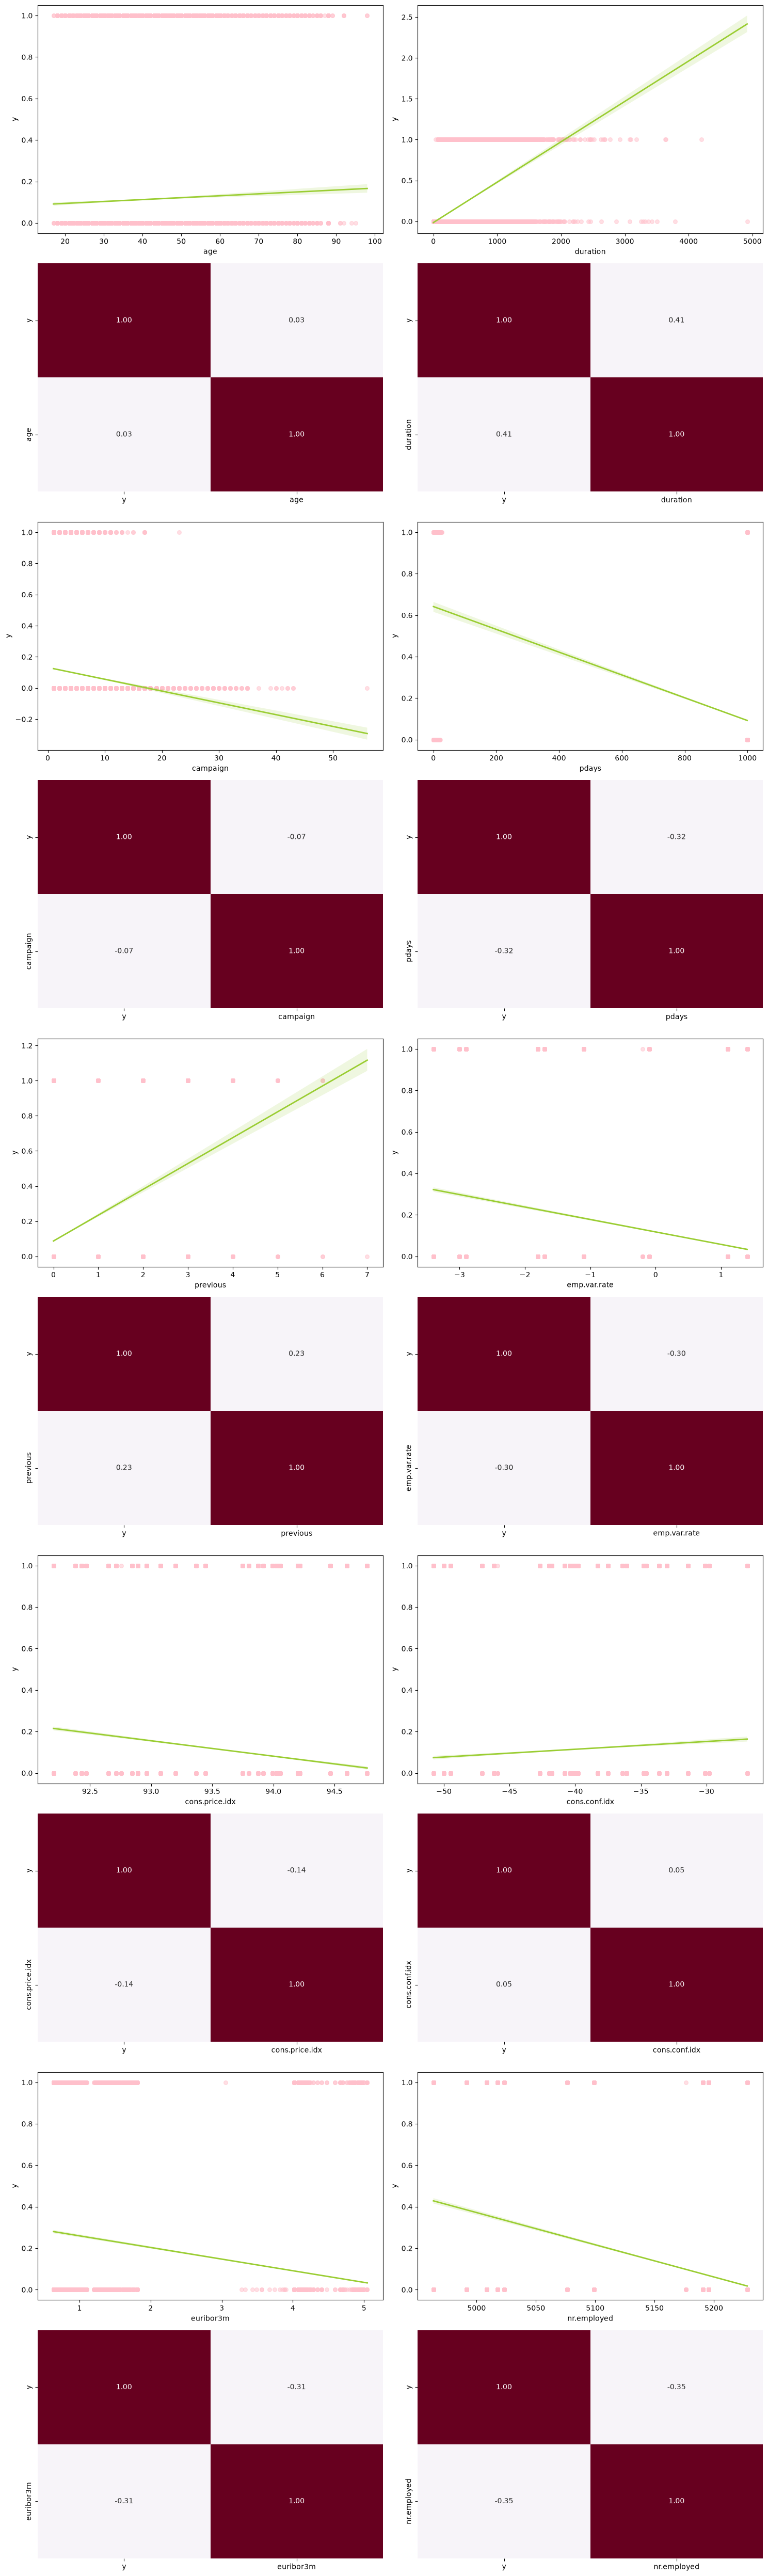

In [166]:
fig, axis = plt.subplots(10, 2, figsize = (15,50))

sns.regplot(ax = axis[0, 0], data = df, x = "age", y = "y", scatter_kws = {'s':30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "age"]].corr(), annot = True, fmt = ".2f", ax = axis[1, 0],cbar = False, cmap='PuRd')
sns.regplot(ax = axis[0, 1], data = df, x = "duration", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "duration"]].corr(), annot = True, fmt = ".2f", ax = axis[1, 1], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[2, 0], data = df, x = "campaign", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "campaign"]].corr(), annot = True, fmt = ".2f", ax = axis[3, 0], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[2,1], data = df, x = "pdays", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "pdays"]].corr(), annot = True, fmt = ".2f", ax = axis[3, 1], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[4,0], data = df, x = "previous", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "previous"]].corr(), annot = True, fmt = ".2f", ax = axis[5, 0], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[4,1], data = df, x = "emp.var.rate", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "emp.var.rate"]].corr(), annot = True, fmt = ".2f", ax = axis[5, 1], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[6,0], data = df, x = "cons.price.idx", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "cons.price.idx"]].corr(), annot = True, fmt = ".2f", ax = axis[7, 0], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[6,1], data = df, x = "cons.conf.idx", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "cons.conf.idx"]].corr(), annot = True, fmt = ".2f", ax = axis[7, 1], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[8,0], data = df, x = "euribor3m", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "euribor3m"]].corr(), annot = True, fmt = ".2f", ax = axis[9, 0], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[8,1], data = df, x = "nr.employed", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "nr.employed"]].corr(), annot = True, fmt = ".2f", ax = axis[9, 1], cbar = False, cmap='PuRd')

plt.tight_layout()

plt.show()

Conclusiones con respecto al gráfico anterior:

- **'age'**: La pendiente es practicamente plana y su correlación con nuestra variable objetivo es muy débil.

- **'duration'**: Pendiente fuertemente ascendente y alta correlación (0,41), por lo que a mayor duraión de la llamada, mayor probabilidad de que contrate un depósito a plazo.

- **'campaign'**: Pendiente descendente y una correlación debilmente negativa por lo que, realizar demasiadas llamadas durante una misma campaña disminuye la tasa de éxito.

- **'pdays'**: Pendiente altamente descendente debido a que la mayoría de los datos se concentran en el valor 999. Su correlación es negativa (-0,32).

- **'previous'**: Pendiente ascendente marcada y correlación alto, o sea, nos muestra el número de contactos en campañas anteriores es un predictor favorable.

- **'emp.var.rate'**: Pendiente descendente marcada y una correlación negativa importante , lo que nos indica que cuando hay alta tasa de variación de empleo, la disposición a contratar baja.

- **'cons.price.idx'**: Pendiente descendente y correlación negativa leve, con lo que podemos inferir que cuando la inflación es más alta, disminuye levemente la probabilidad de contratar.

- **'cons.conf.idx'**: Pendiente practicamente plana, con una correlación positiva muy débil, o sea, un impacto mínimo sobre nuestra variable objetivo.

- **'euribor3m'**: Pendiente fuertemente descendente y correlación alta negativa, indicándonos que cuando la tasa Euribor es alta, reduce significativamente las probabilidades de contratar.

- **'nr.employed'**: Pendiente fuertemente descendente y correlación alta negativa con un comportamiento muy similar a la variable anterior, mostrándonos una alta multicolinealidad con ésta misma.

O sea, las variables con correlaciones más fuertes son: **'duration'**, **'pdays'**, **'previous'**, **'emp.var.rate'**, **'euribor3m'** y **'nr.employed'**.

#### Categórico-Categórico




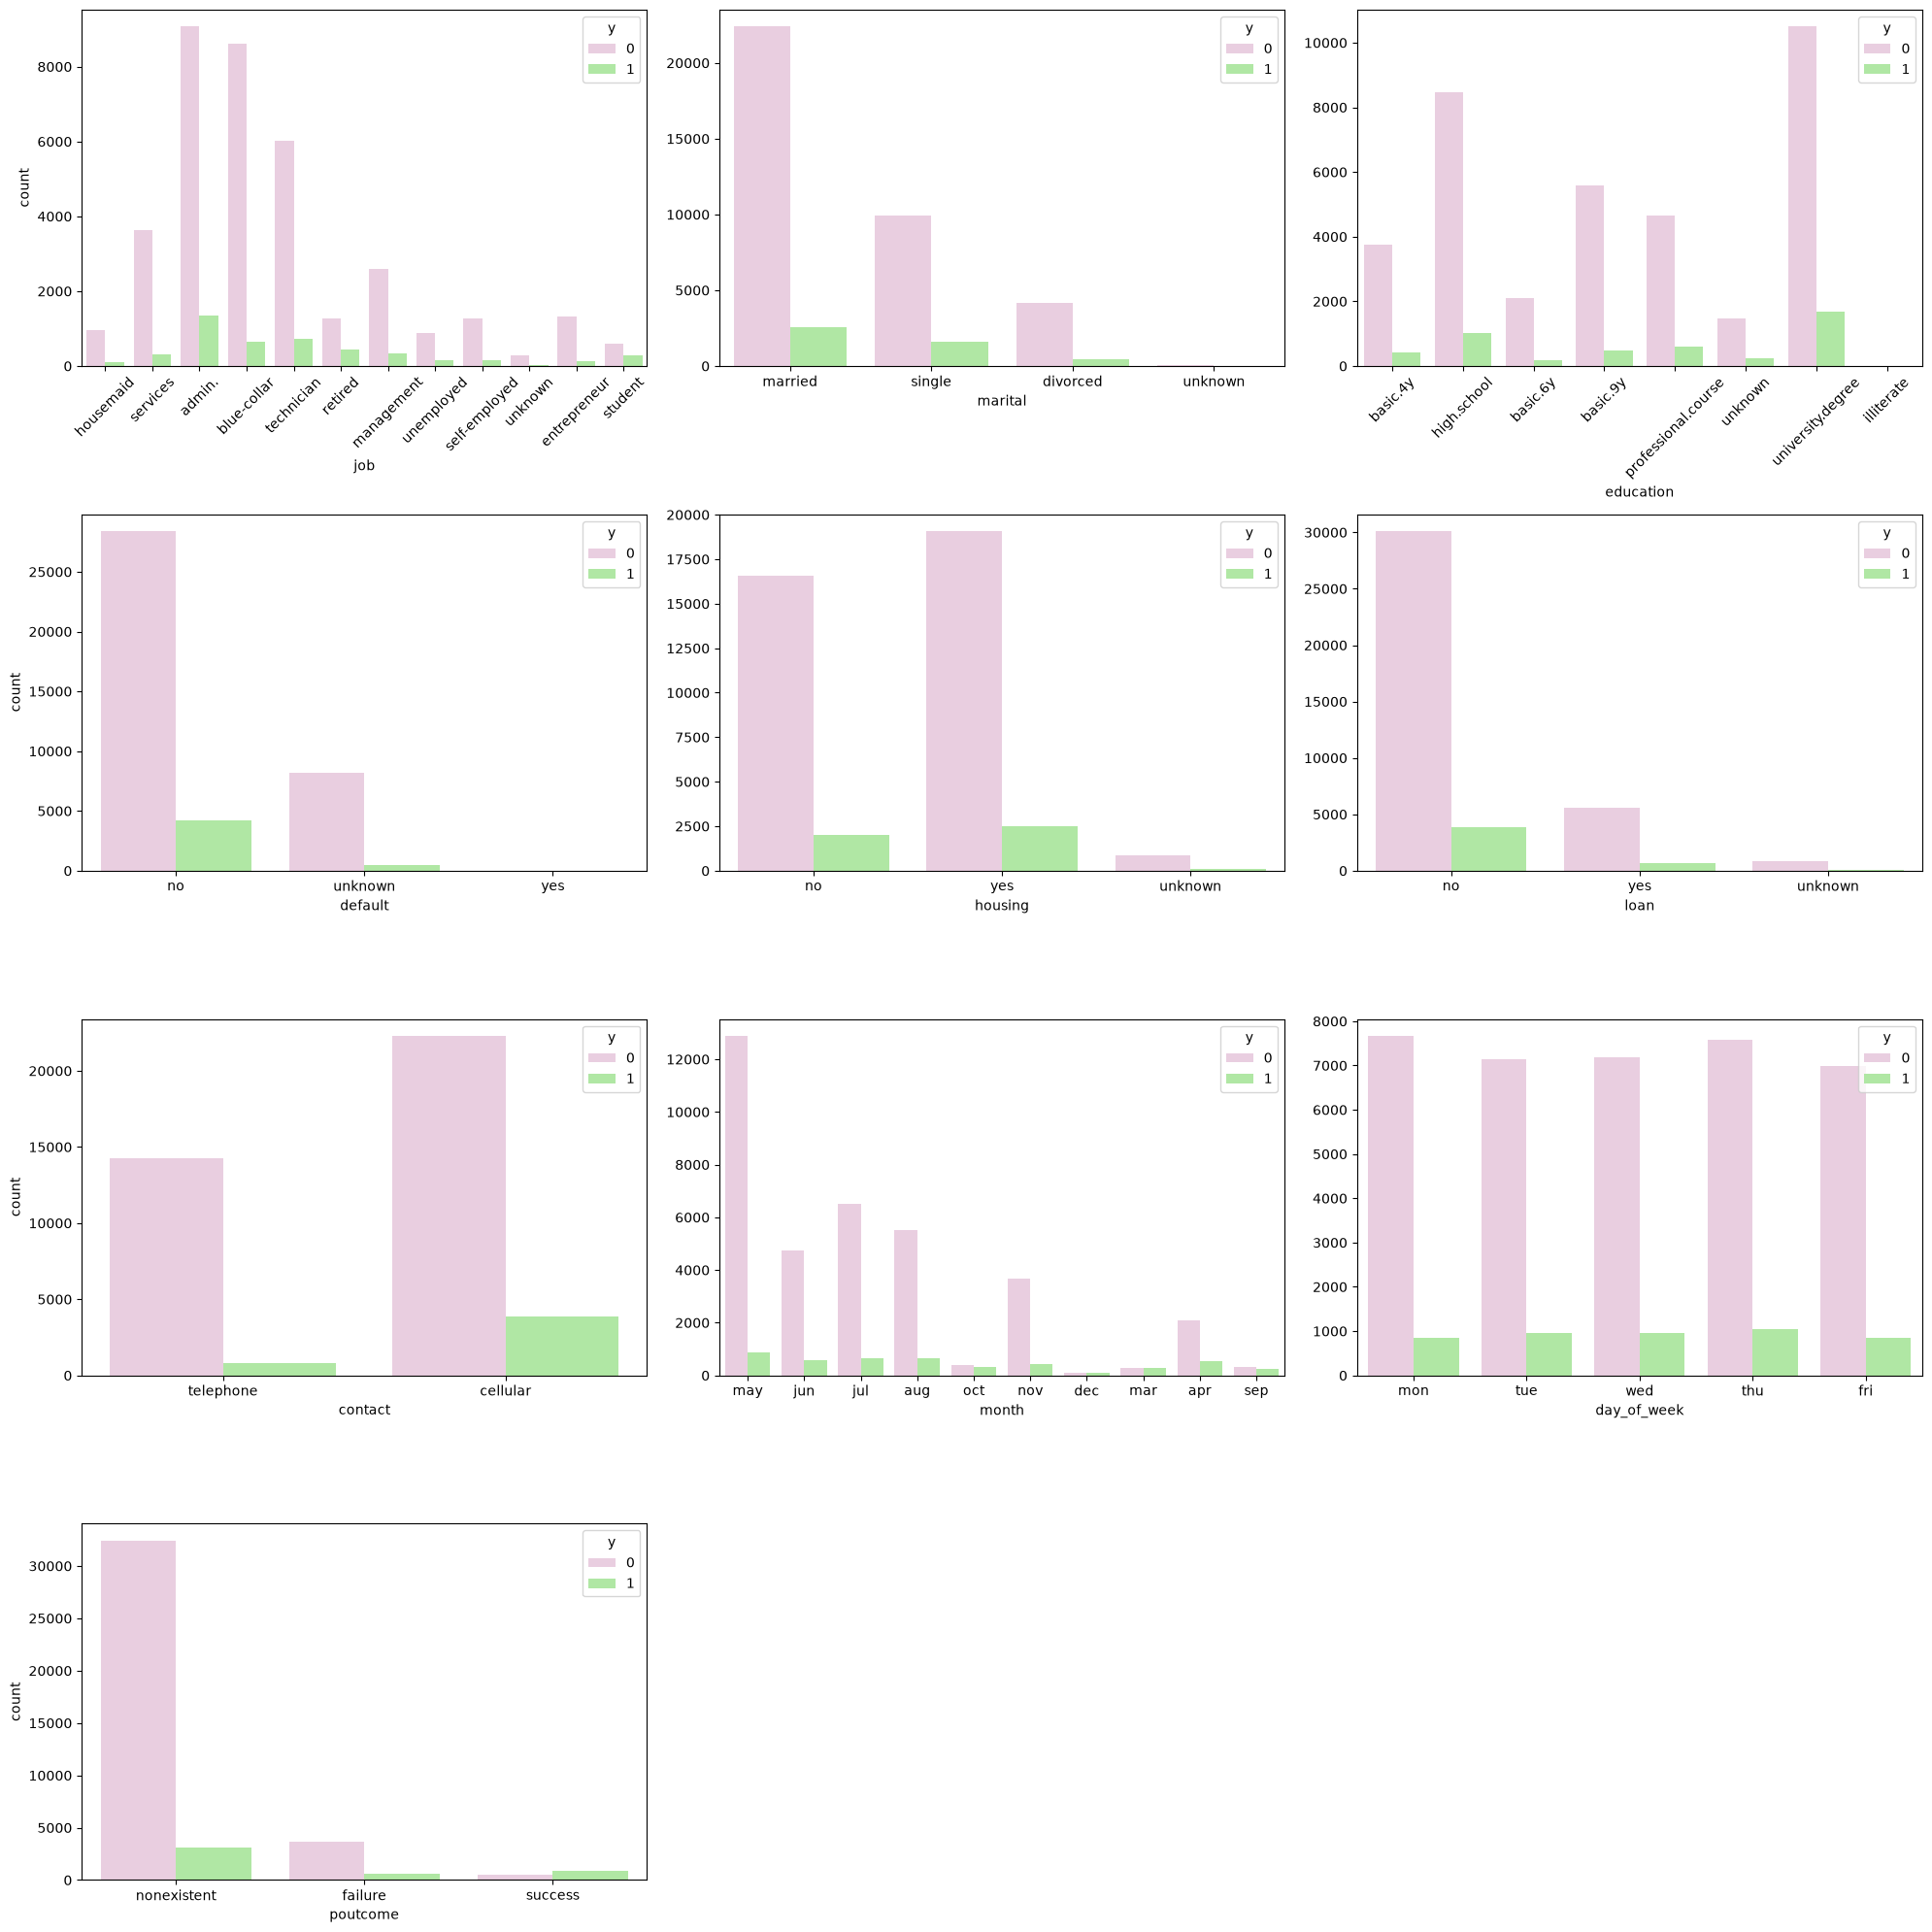

In [175]:
fig, axis = plt.subplots(4, 3, figsize = (20,20))

colores_hue = ['#EDCAE2','#A9F299']

sns.countplot(ax = axis[0, 0], data = df, x = "job", hue = "y", palette = colores_hue).tick_params(axis='x', rotation=45)
sns.countplot(ax = axis[0, 1], data = df, x = "marital", hue = "y", palette = colores_hue).set(ylabel = None)
sns.countplot(ax = axis[0, 2], data = df, x = "education", hue = "y", palette = colores_hue).set(ylabel = None)
axis[0, 2].tick_params(axis='x', rotation=45)
sns.countplot(ax = axis[1, 0], data = df, x = "default", hue = "y", palette = colores_hue)
sns.countplot(ax = axis[1, 1], data = df, x = "housing", hue = "y", palette = colores_hue).set(ylabel = None)
sns.countplot(ax = axis[1, 2], data = df, x = "loan", hue = "y", palette = colores_hue).set(ylabel = None)
sns.countplot(ax = axis[2, 0], data = df, x = "contact", hue = "y", palette = colores_hue)
sns.countplot(ax = axis[2, 1], data = df, x = "month", hue = "y", palette = colores_hue).set(ylabel = None)
sns.countplot(ax = axis[2, 2], data = df, x = "day_of_week", hue = "y", palette = colores_hue).set(ylabel = None)
sns.countplot(ax = axis[3, 0], data = df, x = "poutcome", hue = "y", palette = colores_hue)

fig.delaxes(axis[3, 1])
fig.delaxes(axis[3, 2])

plt.tight_layout()

plt.show()

Analizando los gráficos anteriores concluimos que:

- **'job'**: "admin." y "technician" aportan el mayor volumen de conversiones, sin embargo clasificaciones más pequeñas como "student" y "retired" muestran una tasa de conversión significativamente más alta en relación con su volumen total.

- **'marital'**: Si bien la mayoria de clientes que contratan un depósito a plazo son casados("married"), tiene mayor tasa de conversión los clientes que son solteros("single").

- **'education'**: Los clientes que más tendencia tienen a contratar, son clientes con estudios universitarios("university.degree"), seguido por los que tienen secundaria completa("high.school"), por ende, a mayor estudios, mayor conversión.

- **'default'**: La cantidad de clientes que tienen crédito actualmente es casi nula, por lo que las conversiones suelen se casi todas en los clientes que no tienen credito.

- **'housing'**: La proporción de conversión entre quienes tienen un préstamo hipotecario y quienes no lo tienen, es muy similar entre ellos, por lo que no impacta en la decisión del cliente sobre si contrata, o no, un depósito.

- **'loan'**: Quienes no tienen un préstamo personal concentran casi todas las conversiones. Esta variable no muestra mucha capacidad de discriminación por si sola ante si alguien contrata, o no, un depósito, aunque los datos nos muestran que si no tiene un préstamo personal, facilita que contrate un depósito.

 'contact',
 'month',
 'day_of_week',
 'poutcome',


In [45]:
for columna in categoricas:
    df[columna]=pd.factorize(df[columna])[0]
    
df.info()

<class 'pandas.DataFrame'>
Index: 41176 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41176 non-null  int64  
 1   job             41176 non-null  int64  
 2   marital         41176 non-null  int64  
 3   education       41176 non-null  int64  
 4   default         41176 non-null  int64  
 5   housing         41176 non-null  int64  
 6   loan            41176 non-null  int64  
 7   contact         41176 non-null  int64  
 8   month           41176 non-null  int64  
 9   day_of_week     41176 non-null  int64  
 10  duration        41176 non-null  int64  
 11  campaign        41176 non-null  int64  
 12  pdays           41176 non-null  int64  
 13  previous        41176 non-null  int64  
 14  poutcome        41176 non-null  int64  
 15  emp.var.rate    41176 non-null  float64
 16  cons.price.idx  41176 non-null  float64
 17  cons.conf.idx   41176 non-null  float64
 18  eu

In [46]:
X = df.drop(columns=['y'])
y= df['y']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [51]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_escalados = scaler.fit_transform(X_train)

X_train_escalados = pd.DataFrame(X_train_escalados,columns=X_train.columns, index = X_train.index)

X_test_escalados = scaler.transform(X_test)

X_test_escalados = pd.DataFrame(X_test_escalados, columns=X_test.columns, index = X_test.index)

X_train_escalados.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
12348,0.148148,0.909091,0.000000,0.285714,0.0,0.5,0.5,0.0,0.222222,1.00,0.058154,0.036364,1.0,0.0,0.0,1.000000,0.669135,0.338912,0.980503,1.000000
8565,0.407407,0.181818,0.333333,0.857143,0.0,0.0,0.0,0.0,0.111111,0.50,0.036194,0.090909,1.0,0.0,0.0,1.000000,0.882307,0.376569,0.958966,1.000000
21424,0.148148,0.181818,0.333333,0.857143,0.0,0.0,0.0,1.0,0.333333,0.25,0.020943,0.054545,1.0,0.0,0.0,1.000000,0.484412,0.615063,0.981410,1.000000
3316,0.222222,0.181818,0.333333,0.857143,0.0,0.0,0.0,0.0,0.000000,0.75,0.027450,0.000000,1.0,0.0,0.0,0.937500,0.698753,0.602510,0.958059,0.859735
33246,0.283951,0.272727,0.333333,0.142857,0.5,0.0,0.0,1.0,0.000000,0.25,0.084994,0.000000,1.0,0.0,0.0,0.333333,0.269680,0.192469,0.148946,0.512287


In [48]:
from sklearn.linear_model import LogisticRegression
